# Hydrological modelling - Raven (distributed)

`xHydro` provides a collection of functions designed to facilitate hydrological modelling, focusing on two key models: [HYDROTEL](https://github.com/INRS-Modelisation-hydrologique/hydrotel) and a suite of models emulated by the [Raven Hydrological Framework](https://raven.uwaterloo.ca/). It is important to note that Raven already possesses an extensive Python library, [RavenPy](https://github.com/CSHS-CWRA/RavenPy), which enables users to build, calibrate, and execute models. `xHydro` wraps some of these functions to support multi-model assessments with HYDROTEL, though users seeking advanced functionalities may prefer to use `RavenPy` directly. 

The primary contribution of `xHydro` to hydrological modelling is thus its support for HYDROTEL, a model that previously lacked a dedicated Python library. This Notebook covers `RavenPy` models, but a similar notebook for `HYDROTEL` is available [here](../hydrological_modelling_hydrotel.ipynb).

## Basic information

In [1]:
from IPython.display import clear_output

import xhydro as xh
import xhydro.modelling as xhm

clear_output(wait=False)

In [2]:
import logging

logger = logging.getLogger()
logger.setLevel(logging.CRITICAL)

The `xHydro` modelling framework is based on a `model_config` dictionary, which is meant to contain all necessary information to execute a given hydrological model. For example, depending on the model, it can store meteorological datasets directly, paths to datasets (netCDF files or other), csv configuration files, parameters, and basically anything that is required to configure and execute an hydrological model.

The list of required inputs for the dictionary can be obtained one of two ways. The first is to look at the hydrological model's class, such as `xhydro.modelling.RavenpyModel`. The second is to use the `xh.modelling.get_hydrological_model_inputs` function to get a list of the required keys for a given model, as well as the documentation.

In [3]:
help(xhm.get_hydrological_model_inputs)

Help on function get_hydrological_model_inputs in module xhydro.modelling.hydrological_modelling:

get_hydrological_model_inputs(model_name: str, required_only: bool = False) -> tuple[dict, str]
    Get the required inputs for a given hydrological model.

    Parameters
    ----------
    model_name : str
        The name of the hydrological model to use.
        Currently supported models are ["HYDROTEL", "Blended", "GR4JCN", "HBVEC", "HMETS", "HYPR", "Mohyse", "SACSMA"].
    required_only : bool
        If True, only the required inputs will be returned.

    Returns
    -------
    dict
        A dictionary containing the required configuration for the hydrological model.
    str
        The documentation for the hydrological model.



In [4]:
# This function can be called to get a list of the keys for a given model, as well as its documentation.
inputs, docs = xhm.get_hydrological_model_inputs("HBVEC", required_only=False)
inputs

{'model_name': typing.Optional[typing.Literal['Blended', 'GR4JCN', 'HBVEC', 'HMETS', 'HYPR', 'Mohyse', 'SACSMA']],
 'overwrite': bool,
 'workdir': str | os.PathLike | None,
 'executable': str | os.PathLike | None,
 'run_name': str | None,
 'start_date': datetime.datetime | str | None,
 'end_date': datetime.datetime | str | None,
 'parameters': numpy.ndarray | list[float] | None,
 'qobs_file': os.PathLike | str | None,
 'alt_name_flow': str | None,
 'hru': geopandas.geodataframe.GeoDataFrame | dict | os.PathLike | str | None,
 'output_subbasins': typing.Union[typing.Literal['all', 'qobs'], list[int], NoneType],
 'minimum_reservoir_area': str | None,
 'meteo_file': os.PathLike | str | None,
 'data_type': list[str] | None,
 'alt_names_meteo': dict | None,
 'meteo_station_properties': dict | None,
 'gridweights': str | os.PathLike | None}

In [5]:
print(docs)


    Initialize the RavenPy model class.

    Parameters
    ----------
    overwrite : bool
        If True, overwrite the existing project files. Default is False.
    workdir : str | Path | None
        Path to save the .rv files and model outputs. Default is None, which creates a temporary directory.
    executable : str | os.PathLike | None, optional
        Path to the Raven executable, bypassing RavenPy.
        If None (default), the Raven executable from your current Python environment ('raven-hydro') will be used.
    run_name : str, optional
        Name of the run, which will be used to name the project files. Defaults to "raven" if not provided.
    model_name : {"Blended", "GR4JCN", "HBVEC", "HMETS", "HYPR", "Mohyse", "SACSMA"}, optional
        The name of the RavenPy model to run. Only optional if the project files already exist.
    start_date : dt.datetime | str, optional
        The first date of the simulation. Only optional if the project files already exist.
    e

HYDROTEL and Raven vary in terms of required inputs and available functions, but an effort will be made to standardize the outputs as much as possible. Currently, all models include the following three functions:

- `.run()`: Executes the model, reformats the outputs to be compatible with analysis tools in `xHydro`, and returns the simulated streamflow as a `xarray.Dataset`.
  - The streamflow variable will be named `q` and will have units of `m3 s-1`.
  - For 1D data (such as hydrometric stations), the corresponding dimension in the dataset will be identified by the `cf_role: timeseries_id` attribute.
  
- `.get_inputs()`: Retrieves the meteorological inputs used by the model.

- `.get_outputs()`: Retrieves the simulated outputs from the model.
  - Use `.get_outputs("q")` to obtain the simulated streamflow as a `xarray.Dataset`.

- `.standardize_outputs()`: Standardizes the outputs to ensure consistency across different models, facilitating comparison and analysis. This function is used by default in the `.run()` method, but can also be called separately if needed.

## Initializing and running a calibrated model
Raven requires several `.rv*` files to control various aspects such as meteorological inputs, watershed characteristics, and more. If the project directory already exists and contains data, `xHydro` will prepare the model for execution without overwriting existing `.rv*` files—unless the `overwrite` argument is explicitly set to `True`. To force overwriting of these files, you can thus either:

- Set `overwrite=True` in the `model_config` when instantiating the model
- Use the `.create_rv(overwrite=True)` method on the instantiated model.

This Notebook will focus on distributed RavenPy models. For lumped models, refer to the [Raven lumped modelling notebook](../hydrological_modelling_raven.ipynb).

### Formatting HRU Data for distributed models

Raven relies on Hydrological Response Units (HRUs) for its hydrological simulations, which are typically generated using the [BasinMaker](https://hydrology.uwaterloo.ca/basinmaker/) tool, and specifically its `.Generate_HRUs` function. Thus, `xHydro`'s distributed modelling is currently based on the BasinMaker HRU structure and nomenclature, and uses the `BasinMakerExtractor` class of `RavenPy` to extract the necessary HRU attributes from a shapefile.

Additionally, while BasinMaker will produce attributes such as `Landuse_ID`, these will not be passed on to the `RavenPy` model. Instead, the HRU should contain relevant land use attributes that can be directly mapped to the hydrological model's arguments. For example, for the HBV-EC model, which is currently the only distributed model available in `Raven`, the following attributes are used instead: `LAND_USE_C`, `VEG_C`, and `SOIL_PROF`, which represent land use, vegetation, and soil profile respectively.

<div class="alert alert-info"> <b>INFO</b>

By default, HBV-EC as defined in `RavenPy` only understands a unique `LAND_USE_C` (`LU_ALL`), `VEG_C` (`VEG_ALL`), and `SOIL_PROF` (`DEFAULT_P`). If you want to use different classes, you will need to modify the `model_config` dictionary to include the relevant keys. There is currently no good documentation on how to do this, but you can refer to the class definition of the `HBVEC` model in `ravenpy.config.emulators.hbvec.py`.

As an example, new vegetation classes can be added by modifying the `VegetationClasses` and `VegetationParameterList` keys with new entries detailing all the vegetation classes and their parameters. The same applies to land use and soil profile classes.

</div>

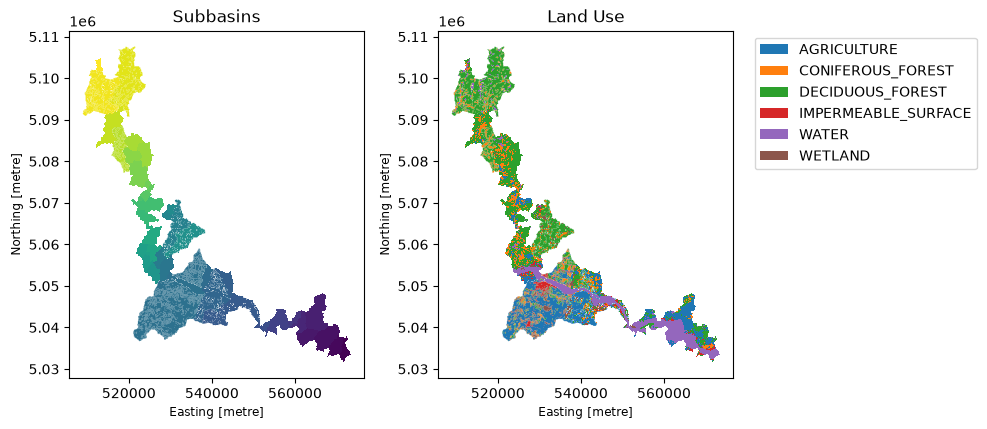

In [6]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pooch

from xhydro.testing.helpers import (  # In-house function to get data from the xhydro-testdata repo
    deveraux,
)

df = gpd.read_file(
    Path(
        deveraux().fetch(
            "ravenpy/hru_subset.zip",
            pooch.Unzip(),
        )[0]
    ).parents[0]
)

# Plot the subbasins and land use
f, ax = plt.subplots(1, 2, figsize=(10, 10))
df.plot(column="SubId", ax=ax[0])
ax[0].set_title("Subbasins")
df.plot(
    column="LAND_USE_C",
    ax=ax[1],
    legend=True,
    legend_kwds={"bbox_to_anchor": (1.05, 1), "loc": "upper left"},
)
ax[1].set_title("Land Use")
plt.tight_layout()

In [7]:
# To keep this example simple, and until cleaner methods are incorporated in xHydro, we will revert to the default HBVEC model configuration.
# This is not recommended for real applications, as you will likely want to modify the model configuration to suit your needs.
df.loc[:, "LAND_USE_C"] = "LU_ALL"
df.loc[:, "VEG_C"] = "VEG_ALL"
df.loc[:, "SOIL_PROF"] = "DEFAULT_P"

### Formatting Meteorological Data

<div class="alert alert-info"> <b>INFO</b>

If using multiple meteorological stations, it is recommended to add the `Interpolation` argument to `model_config` or the `RavenpyModel` call to control the interpolation algorithm. Raven uses the nearest neighbour method by default, but other options are available:

- `INTERP_NEAREST_NEIGHBOR` (default) — Nearest neighbor (Voronoi) method  
- `INTERP_INVERSE_DISTANCE` — Inverse distance weighting  
- `INTERP_INVERSE_DISTANCE_ELEVATION` — Inverse distance weighting with consideration of elevation  
- `INTERP_AVERAGE_ALL` — Averages all specified gauge readings  
- `INTERP_FROM_FILE [filename]` — Weights for each gauge at each HRU are specified in an external file.  This method should work via `xHydro`, but it has not been fully tested.

</div>

<div class="alert alert-info"> <b>INFO</b>

When using gridded meteorological data, `xHydro` uses functions from `RavenPy` to compute weights for each grid cell based on the HRU's geometry.  
Ensure that the domain of the grid completely covers the watershed.

</div>

The acquisition of raw meteorological data is covered in the [GIS notebook](../gis.ipynb) and [Use Case Example](../use_case.ipynb) notebooks. Therefore, this notebook will use a test dataset.

In [8]:
import xarray as xr

ds = xr.open_zarr(
    Path(
        deveraux().fetch(
            "pmp/CMIP.CCCma.CanESM5.historical.r1i1p1f1.day.gn.zarr.zip",
            pooch.Unzip(),
        )[0]
    ).parents[0]
)
ds_fx = xr.open_zarr(
    Path(
        deveraux().fetch(
            "pmp/CMIP.CCCma.CanESM5.historical.r1i1p1f1.fx.gn.zarr.zip",
            pooch.Unzip(),
        )[0]
    ).parents[0]
)

ds["orog"] = ds_fx["orog"]
ds = ds.drop_vars(["height"])
ds["pr"].attrs = {"units": "mm", "long_name": "precipitation"}
ds = ds[["pr", "tas", "orog"]]
ds

<xarray.Dataset> Size: 85kB
Dimensions:  (time: 730, y: 3, x: 3)
Coordinates:
  * time     (time) object 6kB 2010-01-01 12:00:00 ... 2011-12-31 12:00:00
  * y        (y) float64 24B 43.25 46.04 48.84
  * x        (x) float64 24B 281.2 284.1 286.9
Data variables:
    pr       (time, y, x) float64 53kB dask.array<chunksize=(730, 3, 3), meta=np.ndarray>
    tas      (time, y, x) float32 26kB dask.array<chunksize=(730, 3, 3), meta=np.ndarray>
    orog     (y, x) float32 36B dask.array<chunksize=(3, 3), meta=np.ndarray>
Attributes: (12/56)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-his01
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    title:                       CanESM5 output prepared for CMIP6
    tracking_id:                 hdl:21.14100/d0a84c86-7fb1-4de4-8837-574504c...
    variable_id:                 hus
    variant_label:               r1i1p1f1
    version:                     v20190429
    version_id:                  v20190429

Every hydrological model has different requirements when it comes to their input data. In this example, the data above has multiple issues that would be not compatible with the requirements for Raven. For reference on default units expected by Raven, consult [this link](https://ravenpy.readthedocs.io/en/latest/_modules/ravenpy/config/defaults.html#).

The function `xh.modelling.format_input` can be used to reformat CF-compliant datasets for use in hydrological models.

In [9]:
help(xh.modelling.format_input)

Help on function format_input in module xhydro.modelling.hydrological_modelling:

format_input(ds: xarray.core.dataset.Dataset, model: str, convert_calendar_missing: float | str | dict | bool = nan, save_as: str | os.PathLike | None = None, **kwargs) -> tuple[xarray.core.dataset.Dataset, dict]
    Reformat CF-compliant meteorological data for use in hydrological models. See the "Notes" section for important details.

    Parameters
    ----------
    ds : xr.Dataset
        A dataset containing the meteorological data. See the "Notes" section for more information on the expected format.
    model : str
        The name of the hydrological model to use.
        Currently supported models are:
        - "HYDROTEL", "Raven" (which is an alias for all RavenPy models), "Blended", "GR4JCN", "HBVEC", "HMETS", "HYPR", "Mohyse", "SACSMA".
    convert_calendar_missing : float | str | dict | bool, optional
        The value to use for missing values when converting the calendar to "standard".
   

In [10]:
from pathlib import Path
import tempfile
notebook_folder = Path(tempfile.TemporaryDirectory().name)

# You can also use the 'save_as' argument to save the new file(s) in your project folder.
ds_reformatted, config = xh.modelling.format_input(
    ds,
    "HBVEC",
    save_as=notebook_folder / "_data" / "meteo_hmr_distributed.nc",
)
ds_reformatted

/tmp/ipykernel_12615/2541478589.py:6: UserWarning: The calendar 'noleap' needs to be converted to 'standard', but 'convert_calendar_missing' is set to np.nan. NaNs will need to be filled manually before running HYDROTEL or Raven.


/opt/conda/envs/birdy/lib/python3.12/site-packages/clisops/utils/dataset_utils.py:1853: UserWarning: For coordinate variable 'longitude' no bounds can be identified.


<xarray.Dataset> Size: 85kB
Dimensions:    (time: 730, latitude: 3, longitude: 3)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2010-01-01T12:00:00 ... 2011-12-31T1...
  * latitude   (latitude) float64 24B 43.25 46.04 48.84
  * longitude  (longitude) float64 24B -78.75 -75.94 -73.12
    elevation  (latitude, longitude) float32 36B dask.array<chunksize=(3, 3), meta=np.ndarray>
Data variables:
    pr         (time, latitude, longitude) float64 53kB dask.array<chunksize=(730, 3, 3), meta=np.ndarray>
    tas        (time, latitude, longitude) float32 26kB dask.array<chunksize=(730, 3, 3), meta=np.ndarray>
Attributes: (12/56)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-his01
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    title:                       CanESM5 output prepared for CMIP6
    tracking_id:                 hdl:21.14100/d0a84c86-7fb1-4de4-8837-574504c...
    variable_id:                 hus
    variant_label:               r1i1p1f1
    version:                     v20190429
    version_id:                  v20190429

While RavenPy does not require a configuration file to accompany the meteorological file, many information must be given to `model_config` to properly instantiate the model. The second output of `format_input` will return the "meteo_file", "data_type", "alt_names_meteo", and "meteo_station_properties" entries based on the provided file.


In [11]:
config

{'data_type': ['TEMP_AVE', 'PRECIP'],
 'alt_names_meteo': {'TEMP_AVE': 'tas', 'PRECIP': 'pr'},
 'meteo_file': '/tmp/tmp5vekspit/_data/meteo_hmr_distributed.nc'}

### Initializing the Model

The model can now be initialized using the information acquired so far.  
Additional entries can be provided to the `model_config` dictionary, as long as they are supported by the emulated Raven model. In particular:

- The `output_subbasins` key can be used to specify which subbasins to output.
- The `global_parameter` key must have a value for `AVG_ANNUAL_RUNOFF`, which is the average annual runoff in mm/year (with a range of 0-1000 according the Raven's documentation). This value is required for distributed models.

Refer to the [Raven documentation](https://raven.uwaterloo.ca/Downloads.html) for the most up-to-date information.  
Model templates are currently listed in Appendix F, while the available options are described in various chapters.


In [12]:
# The HBVEC model has 21 parameters
parameters = [
    -0.15,
    3.5,
    3.0,
    0.07,
    0.4,
    0.8,
    1,
    4.0,
    0.5,
    0.1,
    1,
    5.0,
    4.8,
    0.1,
    1.0,
    22.0,
    0.5,
    0.1,
    0.0,
    1.0,
    1.0,
]

model_config = {
    "model_name": "HBVEC",
    "workdir": notebook_folder / "hbvec_distributed_simulation",
    "parameters": parameters,
    "global_parameter": {
        "AVG_ANNUAL_RUNOFF": 597
    },  # Distributed models require an average annual runoff value at each HRU
    "hru": df,
    "output_subbasins": "all",  # Use "all" to output all subbasins
    "start_date": "2010-01-02",
    "end_date": "2010-12-31",
    "Evaporation": "PET_HARGREAVES",
    **config,
}

With `model_config` on hand, an instance of the hydrological model can be initialized using `xhydro.modelling.hydrological_model` or the `xhydro.modelling.RavenpyModel` class directly.

In [13]:
hm = xhm.hydrological_model(model_config)
hm

### Validating the Meteorological Data

Before executing hydrological models, a few basic checks will be performed automatically. However, users may want to conduct more advanced health checks on the meteorological inputs (e.g., identifying unrealistic values). This can be done using `xhydro.utils.health_checks`. For the full list of available checks, refer to [the 'xscen' documentation](https://xscen.readthedocs.io/en/latest/notebooks/3_diagnostics.html#Health-checks).

We can use `.get_inputs()` to automatically retrieve the meteorological data. In this example, we'll ensure there are no abnormal meteorological values or sequences of values.


In [14]:
health_checks = {
    "raise_on": [],  # If an entry is not here, it will warn the user instead of raising an exception.
    "flags": {
        "pr": {  # You can have specific flags per variable.
            "negative_accumulation_values": {},
            "very_large_precipitation_events": {},
            "outside_n_standard_deviations_of_climatology": {"n": 5},
            "values_repeating_for_n_or_more_days": {"n": 5},
        },
        "tas": {
            "temperature_extremely_low": {},
            "temperature_extremely_high": {},
            "outside_n_standard_deviations_of_climatology": {"n": 5},
            "values_repeating_for_n_or_more_days": {"n": 5},
        },
    },
}

In [15]:
from xclim.core.units import amount2rate

with hm.get_inputs() as ds_in:
    ds_in["pr"] = amount2rate(ds_in["pr"])  # Precipitation in xclim needs to be a flux.

    xh.utils.health_checks(ds_in, **health_checks)

### Executing the Model

A few basic checks are performed when the `.run()` function is called, before executing the model itself. However, since both RavenPy and Raven will perform a series of checkups themselves, they are kept at a minimum in `xHydro`. If required, a `RavenpyModel.executable` class attribute can be used to point to your own Raven executable instead of the one provided by the `raven-hydro` library in the active Python environment.

Once the model is executed, `xHydro` will automatically reformat the NetCDF file to bring it closer to CF conventions, ensuring compatibility with other `xHydro` modules. Note that, at this time, only the streamflow variable is reformatted, as the modularity of Raven allows for a wide variety of outputs, and it is not yet clear how to standardize all of them. However, dimensions and coordinates will be standardized across all files.

In [16]:
ds_out = hm.run()
ds_out

<xarray.Dataset> Size: 74kB
Dimensions:        (time: 364, subbasin_id: 47)
Coordinates:
  * time           (time) datetime64[ns] 3kB 2010-01-02 ... 2010-12-31
  * subbasin_id    (subbasin_id) <U2 376B '3' '4' '5' '6' ... '47' '48' '49'
    dowsub_id      (subbasin_id) <U2 376B ...
    station_id     (subbasin_id) <U6 1kB ...
    drainage_area  (subbasin_id) float64 376B ...
Data variables:
    q              (time, subbasin_id) float32 68kB ...
Attributes:
    Conventions:      CF-1.6
    featureType:      timeSeries
    history:          Created on 2026-11-12T18:02:34 by Raven 4.12
    description:      Standard Output
    references:       Craig J.R. and the Raven Development Team Raven user's ...
    model_id:         HBVEC
    Raven_version:    4.12
    RavenPy_version:  0.21.1

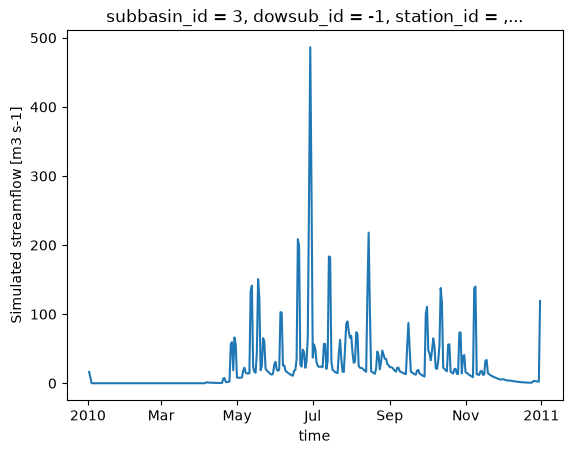

In [17]:
ds_out.isel(subbasin_id=0)["q"].plot()

## Updating the rv* files

Currently, `RavenPy` provides no straightforward way to open and modify the Raven `.rv*` files. For instance, changing simulation dates or meteorological data directly through the files is not yet supported. Until this feature is added, some basic functions have been integrated into `xHydro`, but should be used with care.

The basic information, such as `start_date`, `end_date`, and `parameters`, are stored directly in the `RavenpyModel` class and can be manually updated. Similarly, if additional arguments had been given to the model during initialization, they are stored within a dictionary under `RavenpyModel.kwargs`, which can be accessed and modified as needed.

The observed streamflow, HRU characteristics and meteorological data are stored under the `.qobs`, `.hru` and `.meteo` attributes respectively, but can be much trickier to update, since the associated `RavenPy` commands must be reconstructed again. Therefore, it is strongly recommended to use the `.update_data` method to update these. This function calls upon a subset of the same arguments used when initializing a Raven model:


In [18]:
help(hm.update_data)

Help on method update_data in module xhydro.modelling._ravenpy_models:

update_data(*, qobs_file: os.PathLike | str | None = None, alt_name_flow: str | None = 'q', hru: geopandas.geodataframe.GeoDataFrame | dict | os.PathLike | str | None = None, output_subbasins: Union[Literal['all', 'qobs'], list[int], NoneType] = None, minimum_reservoir_area: str | None = None, meteo_file: os.PathLike | str | None = None, data_type: list[str] | None = None, alt_names_meteo: dict | None = None, meteo_station_properties: dict | None = None, gridweights: str | os.PathLike | None = None) method of xhydro.modelling._ravenpy_models.RavenpyModel instance
    Update the model configuration with new observed data (self.qobs), HRU properties (self.hru), or meteorological data (self.meteo).

    Parameters
    ----------
    qobs_file : os.PathLike | str
        Path to the NetCDF file containing the observed streamflow data.
        If there are multiple stations, the file should contain a 'basin_id' variable

That function will only update the `RavenpyModel` class itself, not the files. If possible, it is strongly recommended to use the `create_rv` function to overwrite the existing `.rv*` files with the updated information.

If this is not possible, some aspects of the model can still be updated using the `.update_config` method:

In [19]:
help(hm.update_config)

Help on method update_config in module xhydro.modelling._ravenpy_models:

update_config(*, rvi_dates: bool = False, rvi_commands: list[str] | None = None, rvt: bool = False, rvh: bool = False) -> None method of xhydro.modelling._ravenpy_models.RavenpyModel instance
    Manually update some aspects of the configuration of the RavenPy model.

    Parameters
    ----------
    rvi_dates : bool
        If True, update the .rvi file with the 'start_date' and 'end_date' defined in the model.
    rvi_commands : list[str] | None
        A list of commands to include in the .rvi file. If None, no additional commands will be added.
    rvt : bool
        If True, update the .rvt file with the meteorological data and observed streamflow data defined in the model.
    rvh : bool
        If True, update the .rvh file with the list of subbasins to output. Nothing else will be changed in that file.

    Notes
    -----
    Ideally, users should favor using the `update_data` method to update the model

Be very aware that not all updates will be reflected in the `.rv*` files. The last two options especially should be used with caution, as HRU characteristics, such as the subbasin IDs, will *not* be updated. If the HRU within the model has changed, there is currently no way to modify existing files. They should be deleted and recreated using the `.create_rv()` method.

## Retrieving additional outputs

By default, Raven produces multiple output files in addition to the streamflow file, which contain various state variables. However, a major limitation is that these files only cover the watershed as a whole, and not the individual HRUs or river segments. The `:CustomOutput` command can be used to specify additional outputs and their spatial resolution. The easiest way to generate these is to use the `update_config` method.

Information on how to use the `:CustomOutput` command can be found in the [Raven documentation](https://raven.uwaterloo.ca/Downloads.html).

In [20]:
hm.update_config(
    rvi_commands=[":CustomOutput DAILY CUMULSUM SNOW BY_HRU"]
)
hm.run(overwrite=True, return_streamflow=False)

The `.get_outputs()` function can be used to retrieve any of these variables as a `xarray.Dataset`.

In [21]:
help(hm.get_outputs)

Help on method get_outputs in module xhydro.modelling._ravenpy_models:

get_outputs(output: str, return_paths: bool = False, **kwargs) -> xarray.core.dataset.Dataset | pathlib.Path | list[pathlib.Path] method of xhydro.modelling._ravenpy_models.RavenpyModel instance
    Return the outputs of the Raven model.

    Parameters
    ----------
    output : str
        "path" to return the output directory.
        "q" to only return the streamflow variable.
        Alternatively, a string matching the name of the output file to return (e.g. "Hydrographs", "Storage", "ByHRU", etc.).
        Wildcards can be used.
    return_paths : bool
        If True, return the path to the output file(s) instead of the dataset. Default is False.
    \*\*kwargs : dict
        Keyword arguments to pass to :py:func:`xarray.open_dataset`.

    Returns
    -------
    xr.Dataset
        The requested output variable.
    Path
        The path to the output directory if output is set to "path".
    list[Path]
 

In [22]:
files = hm.get_outputs("*", return_paths=True)
files

[PosixPath('/tmp/tmp5vekspit/hbvec_distributed_simulation/output/raven_Hydrographs.nc'),
 PosixPath('/tmp/tmp5vekspit/hbvec_distributed_simulation/output/raven_WatershedStorage.nc'),
 PosixPath('/tmp/tmp5vekspit/hbvec_distributed_simulation/output/raven_SNOW_Daily_CumulSum_ByHRU.nc')]

In [23]:
snow = hm.get_outputs("SNOW*")
snow

<xarray.Dataset> Size: 265kB
Dimensions:                      (time: 363, unit_id: 166)
Coordinates: (12/14)
  * time                         (time) datetime64[ns] 3kB 2010-01-03 ... 201...
  * unit_id                      (unit_id) <U3 2kB '1' '2' '3' ... '165' '166'
    dowsub_id                    (unit_id) <U2 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    station_id                   (unit_id) <U6 4kB dask.array<chunksize=(166,), meta=np.ndarray>
    subbasin_id                  (unit_id) <U2 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    subbasin_centroid_longitude  (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    ...                           ...
    unit_centroid_latitude       (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    drainage_area                (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    subbasin_drainage_area       (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    unit_drainage_area           (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    subbasin_elevation           (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
    unit_elevation               (unit_id) float64 1kB dask.array<chunksize=(166,), meta=np.ndarray>
Data variables:
    CumulSum_SNOW                (time, unit_id) float32 241kB dask.array<chunksize=(1, 166), meta=np.ndarray>
Attributes:
    Conventions:      CF-1.6
    featureType:      timeSeries
    history:          Created on 2026-11-12T18:02:34 by Raven 4.12
    description:      Custom Output
    references:       Craig J.R. and the Raven Development Team Raven user's ...
    model_id:         HBVEC
    Raven_version:    4.12
    RavenPy_version:  0.21.1

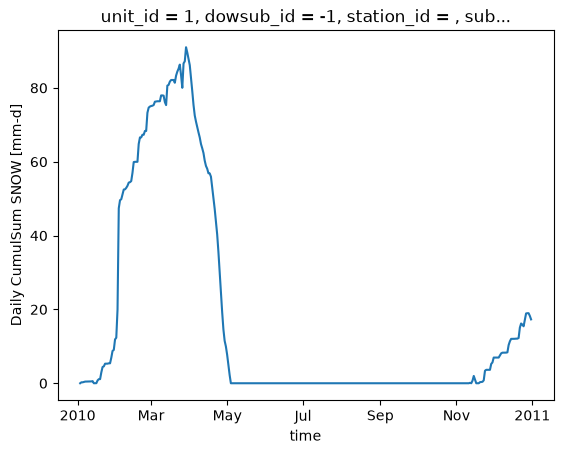

In [24]:
snow["CumulSum_SNOW"].isel(unit_id=0).plot()

A few important notes regarding the use of `:CustomOutput` in `xHydro`:
- Due to the very high modularity of these outputs, there is currently no standardization of the variable names or their units.
- Furthermore, some of these variables are cumulative, while others are not, and there is currently no way to automatically identify them. It is thus the user's responsibility to ensure that the variables are properly interpreted.
- In an effort to standardize the outputs across different models, the following aggregation levels have been defined. These are noted in a `aggregation_level` attribute in the variable's metadata, and can be used to identify the spatial resolution of the output:
  - `ComputationalUnit`: In Raven, this corresponds to the Hydrological Response Units (HRUs).
  - `Subbasin`: Following the Raven convention, this corresponds to the immediate drainage area of a river segment, excluding the upstream drainage area.
  - `DrainageArea`: This corresponds to the cumulative drainage area of a river segment.

The `CustomOutput` command allows a control on the spatial resolution of the output (`BY_HRU`, `BY_SUBBASIN`, `BY_DRAINAGE_AREA`), but a `aggregate_outputs` function has additionally been implemented in `xHydro` to allow the aggregation of outputs in post-processing, if needed. Note that this function relies on multiple watershed properties which are deduced from the provided HRU shapefile and will fail if the HRU characteristics do not follow the BasinMaker structure and nomenclature.

In [25]:
help(hm.aggregate_outputs)

Help on method aggregate_outputs in module xhydro.modelling._ravenpy_models:

aggregate_outputs(by: Literal['hru', 'unit', 'subbasin'], to: Literal['subbasin', 'drainage_area'], subset: list[str] | None = None, **kwargs) -> None method of xhydro.modelling._ravenpy_models.RavenpyModel instance
    Aggregate the model outputs to a different spatial unit. See the Notes section for more details.

    Parameters
    ----------
    by : {"hru", "unit", "subbasin"}
        The spatial unit to aggregate from.
        "unit" is the generic term for "hru".
    to : {"subbasin", "drainage_area"}
        The spatial unit to aggregate to.
    subset : list[str] | None
        The list of variables to aggregate. If None, all variables will be processed.
        The strings should match the names produced by the Raven model, typically found under ":CustomOutput" in the .rvi file.
    \*\*kwargs : dict
        Keyword arguments to pass to :py:func:`xarray.open_dataset`.

    Returns
    -------
    No

In [26]:
hm.aggregate_outputs(by="hru", to="drainage_area")

In [27]:
snow_agg = hm.get_outputs("SNOW*Drainage*")
snow_agg

<xarray.Dataset> Size: 142kB
Dimensions:        (time: 363, subbasin_id: 47)
Coordinates:
  * time           (time) datetime64[ns] 3kB 2010-01-03 ... 2010-12-31
  * subbasin_id    (subbasin_id) <U2 376B '3' '4' '5' '6' ... '47' '48' '49'
    dowsub_id      (subbasin_id) <U2 376B dask.array<chunksize=(47,), meta=np.ndarray>
    station_id     (subbasin_id) <U6 1kB dask.array<chunksize=(47,), meta=np.ndarray>
    drainage_area  (subbasin_id) float64 376B dask.array<chunksize=(47,), meta=np.ndarray>
Data variables:
    CumulSum_SNOW  (time, subbasin_id) float64 136kB dask.array<chunksize=(363, 47), meta=np.ndarray>
Attributes:
    Conventions:      CF-1.6
    featureType:      timeSeries
    history:          Created on 2026-11-12T18:02:34 by Raven 4.12
    description:      Custom Output
    references:       Craig J.R. and the Raven Development Team Raven user's ...
    model_id:         HBVEC
    Raven_version:    4.12
    RavenPy_version:  0.21.1

## Model Calibration

Calibrating distributed models is not yet supported by `xHydro` if multiple hydrometric stations are used. Users are encouraged to use the `RavenPy` library directly for this purpose. For single-station calibration, `xHydro` can be used. Refer to the [lumped RavenPy documentation](../hydrological_modelling_raven.ipynb) for more details.